In [ ]:
#Step 1 - Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler

In [ ]:
#Step 2 - Mount Google Drive and replace the paths with the actual paths to your CSV files in Google Drive

from google.colab import drive
drive.mount('/content/drive')

featuredvariables_path = '/content/drive/MyDrive/Data Mining Principles/FinMark datasets/Customer_Profile_For_Recommendation.csv'

# Load the datasets
featuredvariables_df = pd.read_csv(featuredvariables_path)

Mounted at /content/drive


In [ ]:
featuredvariables_df['high_value_txn_ratio'] = (
    featuredvariables_df['high_value_txn_ratio'].fillna(0)
)

featuredvariables_df["transaction_ratio"] = np.where( featuredvariables_df["total_transaction_count"] != 0,
featuredvariables_df["total_transaction_amount"] / featuredvariables_df["total_transaction_count"], np.nan )
featuredvariables_df["transaction_ratio"] = featuredvariables_df["transaction_ratio"].fillna(0)

print(featuredvariables_df.head())

   Customer_ID  total_transaction_amount  avg_transaction_amount income_level  \
0            1                   16795.0             2799.166667       Medium   
1            2                    4907.0             2453.500000       Medium   
2            3                    1538.0             1538.000000          Low   
3            4                    8295.0             4147.500000         High   
4            5                   14798.0             2959.600000         High   

   income_level_encoded  bill_payment_count  loan_payment_count  \
0                     1                   3                   1   
1                     1                   1                   1   
2                     0                   1                   0   
3                     2                   0                   1   
4                     2                   2                   0   

   investment_count  purchase_count  total_transaction_count  ...  \
0                 1               1      

In [ ]:
#Step 3: Scale Numeric Features for Clustering ---
# Rationale:
# Numeric features in the dataset (transaction amounts, counts, high-value transaction counts, etc.)
# have different scales. If not scaled, features with larger magnitudes (e.g., total_transaction_amount)
# would dominate distance calculations in clustering. To ensure all features contribute equally,
# Z-score standardization is applied, transforming each feature to zero mean and unit variance.

# --- 1. Select numeric/count features to scale ---
scale_cols = [
    'total_transaction_amount', 'income_level_encoded', 'total_transaction_count',
    'high_value_txn_count', 'high_value_txn_ratio', 'transaction_ratio',
    'avg_satisfaction_score', 'engagement_count', 'avg_ltr', 'loyalty_flag',
]

# --- 2. Copy dataset to avoid overwriting original data ---
featuredvariables_scaled = featuredvariables_df.copy()

# --- 3. Apply StandardScaler (Z-score scaling) ---
scaler_z = StandardScaler()
featuredvariables_scaled[scale_cols] = scaler_z.fit_transform(featuredvariables_scaled[scale_cols])

# --- 4. Print first 5 rows of scaled features for verification ---
print("\n--- Z-score Scaled Features (first 5 rows) ---")
print(featuredvariables_scaled[scale_cols].head())


--- Z-score Scaled Features (first 5 rows) ---
   total_transaction_amount  income_level_encoded  total_transaction_count  \
0                  0.665247              0.001413                 0.451018   
1                 -1.159791              0.001413                -1.353055   
2                 -1.676998             -1.411390                -1.804073   
3                 -0.639668              1.414216                -1.353055   
4                  0.358669              1.414216                 0.000000   

   high_value_txn_count  high_value_txn_ratio  transaction_ratio  \
0              3.528817              2.378188           0.403274   
1             -0.499513             -0.432194          -0.027635   
2             -0.499513             -0.432194          -1.168899   
3             -0.499513             -0.432194           2.084109   
4              1.514652              1.254035           0.603271   

   avg_satisfaction_score  engagement_count   avg_ltr  loyalty_flag  
0   


--- PCA Explained Variance Ratio per Component ---
PC1: 0.2961
PC2: 0.1599
PC3: 0.1556
PC4: 0.1214
PC5: 0.0996
PC6: 0.0965
PC7: 0.0436
PC8: 0.0150
PC9: 0.0094
PC10: 0.0030

--- Cumulative Explained Variance ---
PC1 to PC1: 0.2961
PC1 to PC2: 0.4560
PC1 to PC3: 0.6116
PC1 to PC4: 0.7330
PC1 to PC5: 0.8326
PC1 to PC6: 0.9291
PC1 to PC7: 0.9727
PC1 to PC8: 0.9876
PC1 to PC9: 0.9970
PC1 to PC10: 1.0000

--- PCA Loadings (Feature Contributions to Each Component) ---
                             PC1     PC2     PC3     PC4     PC5     PC6  \
total_transaction_amount  0.4394  0.4412  0.2437  0.0196 -0.0693  0.0502   
income_level_encoded      0.4478 -0.1137 -0.0642 -0.4938  0.0109  0.1672   
total_transaction_count   0.2487  0.5857  0.3298  0.2498 -0.0667 -0.0328   
high_value_txn_count      0.4216 -0.1895 -0.1318  0.4996  0.0465 -0.1393   
high_value_txn_ratio      0.3768 -0.3441 -0.2505  0.4096  0.0809 -0.1492   
transaction_ratio         0.4714 -0.1406 -0.0739 -0.4321 -0.0008  0.1377   
a

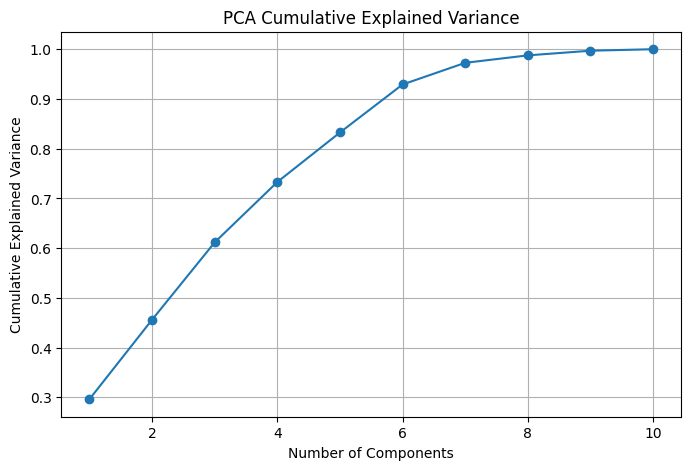

In [ ]:
# Step 4: PCA for Dimensionality Reduction Before Clustering
from sklearn.decomposition import PCA

# --- 1. Select the same scaled numeric features ---
X_scaled = featuredvariables_scaled[scale_cols]

# --- 2. Initialize PCA ---
# Keep enough components to inspect variance; choose later how many to retain
pca = PCA()
pca_components = pca.fit_transform(X_scaled)

# --- 3. Explained variance ratio ---
explained_variance = pca.explained_variance_ratio_
cumulative_variance = explained_variance.cumsum()

print("\n--- PCA Explained Variance Ratio per Component ---")
for i, var in enumerate(explained_variance):
    print(f"PC{i+1}: {var:.4f}")

print("\n--- Cumulative Explained Variance ---")
for i, cum_var in enumerate(cumulative_variance):
    print(f"PC1 to PC{i+1}: {cum_var:.4f}")

# --- 4. Create a DataFrame for PCA loadings (feature contributions) ---
loadings_df = pd.DataFrame(
    pca.components_.T,
    columns=[f"PC{i+1}" for i in range(len(scale_cols))],
    index=scale_cols
)

print("\n--- PCA Loadings (Feature Contributions to Each Component) ---")
print(loadings_df.round(4))

# --- 5. Plot cumulative variance ---
plt.figure(figsize=(8,5))
plt.plot(range(1, len(cumulative_variance)+1), cumulative_variance, marker='o')
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Cumulative Explained Variance")
plt.grid(True)
plt.show()

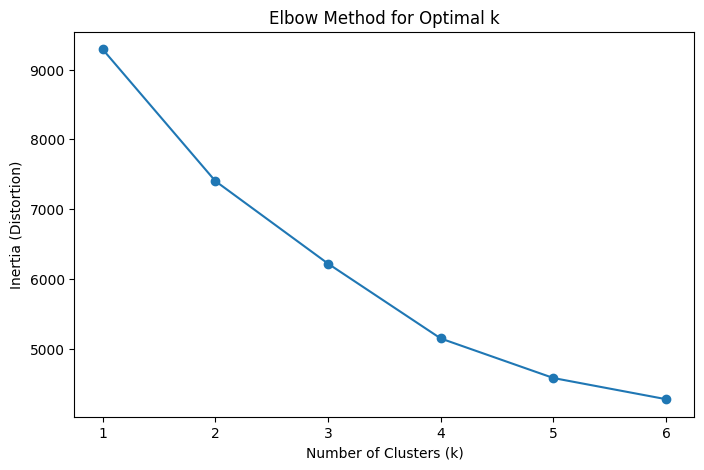


--- Inertia Values ---
k = 1: inertia = 9290.94
k = 2: inertia = 7403.04
k = 3: inertia = 6219.49
k = 4: inertia = 5147.12
k = 5: inertia = 4580.52
k = 6: inertia = 4277.27


In [ ]:
# Step 5: Elbow Method to Determine Optimal Number of Clusters
from sklearn.cluster import KMeans

# --- 2. Choose how many PCA components to use ---
num_components = 6

X_pca = pca_components[:, :num_components]   #Extract those PCA scores

# --- 3. Compute inertia for k = 1 to 10 ---
inertia = []
K_range = range(1, 7) #Try different numbers of clusters (k = 1 to 10)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_pca)
    inertia.append(kmeans.inertia_)

# --- Plot the elbow curve ---
plt.figure(figsize=(8,5))
plt.plot(K_range, inertia, marker='o')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia (Distortion)")
plt.title("Elbow Method for Optimal k")
plt.grid(False)
plt.show()

# --- Print inertia values for reference ---
print("\n--- Inertia Values ---")
for k, val in zip(K_range, inertia):
    print(f"k = {k}: inertia = {val:.2f}")


K-Means with k=3
Silhouette Score: 0.1913
Calinski-Harabasz Score: 246.19


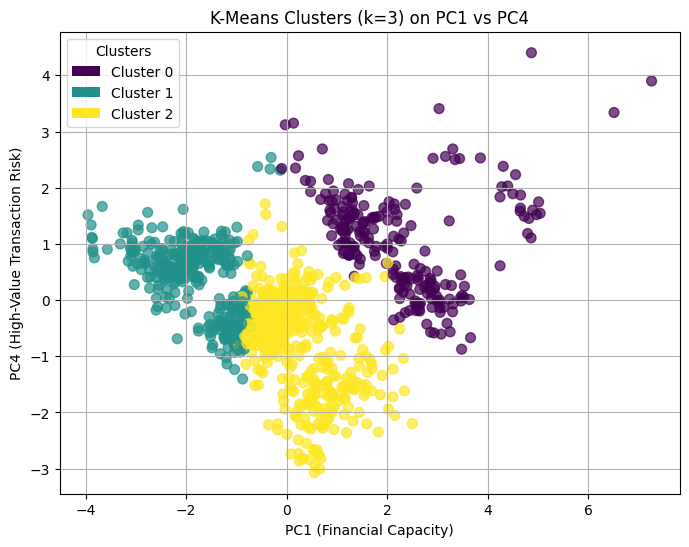

In [ ]:
#Step 6: Apply K‑Means on PCA Components (k = 3) + Evaluation metrics + Visualization

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score

# --- 1. Choose number of clusters ---
k = 3

# --- 2. Fit K-Means on PCA components ---
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_pca)

# --- 3. Add cluster labels to your dataframe ---
featuredvariables_scaled["KMeans_Cluster"] = cluster_labels

# --- 4. Print evaluation metrics ---
sil_score = silhouette_score(X_pca, cluster_labels)
ch_score = calinski_harabasz_score(X_pca, cluster_labels)

print(f"\nK-Means with k={k}")
print(f"Silhouette Score: {sil_score:.4f}")
print(f"Calinski-Harabasz Score: {ch_score:.2f}")

# --- 5. Scatterplot using first two PCA components ---
plt.figure(figsize=(8,6))
plt.scatter(
    X_pca[:, 0], # PC1
    X_pca[:, 3], # PC
    c=cluster_labels,
    cmap='viridis',
    s=50,
    alpha=0.7
)
plt.xlabel("PC1 (Financial Capacity)")
plt.ylabel("PC4 (High-Value Transaction Risk)")
plt.title(f"K-Means Clusters (k={k}) on PC1 vs PC4")
plt.grid(True)

# --- Legend for clusters ---
unique_clusters = sorted(set(cluster_labels))
legend_elements = [
    Patch(facecolor=plt.cm.viridis(i / (k-1)), label=f"Cluster {i}")
    for i in unique_clusters
]

plt.legend(handles=legend_elements, title="Clusters")
plt.show()

In [ ]:
# Count customers in each cluster
cluster_counts = pd.Series(cluster_labels).value_counts().sort_index()

# Convert to percentages
cluster_percentages = (cluster_counts / len(cluster_labels)) * 100

print("Customer Count per Cluster:")
print(cluster_counts)

print("\nCustomer Percentage per Cluster:")
print(cluster_percentages.round(2))

Customer Count per Cluster:
0    217
1    330
2    453
Name: count, dtype: int64

Customer Percentage per Cluster:
0    21.7
1    33.0
2    45.3
Name: count, dtype: float64
